# GSEA WT 3v3: top and cross-center consistent terms

This notebook summarizes the completed results in `GSEA_expanded_WT_3v3/full_observed_results.csv`; it does **not** rerun GSEA. The primary statistic is `NES_WT`, with `q_WT` from the source-adjusted WT-versus-WT 3v3 empirical reference. Observed enrichment scores use all eligible KO and control samples in each original comparison.

The goal is to distinguish two questions:

1. **Top within one comparison:** smallest collection-specific `q_WT`, then largest `|NES_WT|`.
2. **Consistent across comparisons:** recurrent significance with the same enrichment direction across JAX, MSK, UCSF, NW, and NW-parent for one perturbed gene. NKX2-1/MSK is excluded from term selection and display because of its documented differentiation failure.

Positive NES means the gene set is concentrated toward genes increased in KO relative to control; negative NES means concentration toward genes decreased in KO.

In [1]:
suppressPackageStartupMessages({
  library(data.table)
  library(dplyr)
  library(ggplot2)
  library(stringr)
  library(scales)
})

theme_set(theme_classic(base_size = 12))
options(repr.plot.width = 14, repr.plot.height = 15, repr.plot.res = 130)

target_order <- c("EOMES", "GCM1", "ISL1", "NKX2-1")
contrast_order <- c("JAX", "MSK", "UCSF", "NW", "NW_parent")
collection_order <- c("Hallmark", "Reactome", "GO_BP", "ReMap", "Custom_ChIP")

q_cutoff <- 0.05
min_direction_fraction <- 0.80
min_significant_contrasts <- 3L # significant in the consensus direction
top_n_per_direction <- 3L

candidate_dirs <- c(
  "GSEA_expanded_WT_3v3",
  file.path("scripts", "GSEA_expanded_WT_3v3"),
  file.path("Code", "MorPhiC", "exchange-experiment-analysis", "scripts", "GSEA_expanded_WT_3v3")
)
gsea_dir <- candidate_dirs[dir.exists(candidate_dirs)][1]
if (is.na(gsea_dir)) stop("Could not find GSEA_expanded_WT_3v3 from the current working directory.")

required_columns <- c(
  "target", "contrast", "collection", "pathway", "size", "ES",
  "p_WT", "NES_WT", "q_WT", "p_prerank", "NES_prerank", "q_prerank"
)

gsea_results <- data.table::fread(
  file.path(gsea_dir, "full_observed_results.csv"),
  select = required_columns,
  data.table = FALSE
) %>%
  mutate(
    target = factor(target, levels = target_order),
    contrast = factor(contrast, levels = contrast_order, ordered = TRUE),
    collection = factor(collection, levels = collection_order),
    term_label = case_when(
      collection == "ReMap" ~ str_remove(pathway, "^REMAP__"),
      TRUE ~ pathway %>%
        str_remove("^(HALLMARK_|REACTOME_|GOBP_|CUSTOM_CHIP__)") %>%
        str_replace_all("_", " ")
    )
  )

duplicate_keys <- gsea_results %>%
  count(target, contrast, collection, pathway) %>%
  filter(n != 1)
stopifnot(nrow(duplicate_keys) == 0)

# Keep the complete source table intact, but omit the failed NKX2-1/MSK
# comparison from cross-center selection and the final heatmaps.
selection_results <- gsea_results %>%
  filter(!(as.character(target) == "NKX2-1" & as.character(contrast) == "MSK"))

cat("Loaded", format(nrow(gsea_results), big.mark = ","), "pathway-comparison results from", gsea_dir, "\n")

Loaded 107,105 pathway-comparison results from GSEA_expanded_WT_3v3 


## What the retained folder currently selects

The complete table contains every tested term. `q_WT` is BH-adjusted **within each target, comparison, and collection**, before display selection. The retained overview is not a cross-center consistency analysis:

- all 50 Hallmark sets are shown;
- previously selected Reactome and ReMap rows are frozen in `inputs/Reactome_ReMap_display_selection.csv`;
- the saved selection has three positive and three negative rows per target and collection, identified through a single comparison and `selection_abs_WT_NES`;
- previously selected nonredundant GO rows are also kept fixed; and
- the one custom ChIP set is shown directly.

Therefore, a row can appear in the overview because it had a large effect in one comparison, even if it is not significant or directionally consistent across the other comparisons. The audit below verifies this directly from the retained selection table.

In [2]:
result_scope <- gsea_results %>%
  group_by(target, collection) %>%
  summarise(
    comparisons = n_distinct(contrast),
    tested_terms = n_distinct(pathway),
    significant_term_comparisons = sum(q_WT < q_cutoff, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  arrange(target, collection)

result_scope

target,collection,comparisons,tested_terms,significant_term_comparisons
<fct>,<fct>,<int>,<int>,<int>
EOMES,Hallmark,5,50,47
EOMES,Reactome,5,1033,370
EOMES,GO_BP,5,3997,2769
EOMES,ReMap,5,294,12
EOMES,Custom_ChIP,5,1,5
GCM1,Hallmark,5,50,25
GCM1,Reactome,5,1026,200
GCM1,GO_BP,5,3951,495
GCM1,ReMap,5,294,20


In [3]:
display_selection_file <- file.path(gsea_dir, "inputs", "Reactome_ReMap_display_selection.csv")
stopifnot(file.exists(display_selection_file))

display_selection <- data.table::fread(display_selection_file, data.table = FALSE)

display_selection_audit <- display_selection %>%
  left_join(
    gsea_results %>%
      transmute(
        selected_for_target = as.character(target),
        selection_contrast = as.character(contrast),
        collection = as.character(collection),
        pathway, current_NES_WT = NES_WT, current_q_WT = q_WT
      ),
    by = c("selected_for_target", "selection_contrast", "collection", "pathway")
  )

display_selection_audit %>%
  group_by(collection, selected_for_target, selected_for_direction) %>%
  summarise(
    selected_rows = n(),
    currently_significant = sum(current_q_WT < q_cutoff, na.rm = TRUE),
    currently_not_significant = sum(current_q_WT >= q_cutoff, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  arrange(collection, selected_for_target, selected_for_direction)

collection,selected_for_target,selected_for_direction,selected_rows,currently_significant,currently_not_significant
<chr>,<chr>,<chr>,<int>,<int>,<int>
ReMap,EOMES,down,3,2,1
ReMap,EOMES,up,3,0,3
ReMap,GCM1,down,3,3,0
ReMap,GCM1,up,3,0,3
ReMap,ISL1,down,3,0,3
ReMap,ISL1,up,3,0,3
ReMap,NKX2-1,down,3,1,2
ReMap,NKX2-1,up,3,2,1
Reactome,EOMES,down,3,3,0


## Reproducible definitions used here

For each gene perturbation and collection, terms are summarized over the available comparisons. NKX2-1/MSK is omitted from this summary and from the heatmaps; the complete source table is unchanged. A term is flagged `consistent_WT` when:

- at least 80% of available comparisons have the same NES sign (4/5 for EOMES, GCM1, and ISL1; 4/4 for NKX2-1); and
- at least three available comparisons have `q_WT < 0.05` in that consensus direction.

Terms are ranked separately within each gene perturbation, collection, and consensus direction by: (1) number of significant comparisons in the consensus direction, (2) sign agreement, (3) support from both WT and preranked references, (4) median absolute WT NES, (5) best WT q-value, and (6) pathway identifier as a deterministic tie-breaker. The selected display terms are the top three positive and top three negative terms from those rankings.

`consistent_both_references` is a stricter sensitivity flag requiring at least three comparisons to be significant and directionally concordant under both `q_WT`/`NES_WT` and `q_prerank`/`NES_prerank`. It does not replace the primary WT-reference result. Counts across centers are descriptive reproducibility summaries, not a pooled p-value or an additional FDR procedure.

In [4]:
# Top terms for an individual comparison: q_WT first, then absolute NES_WT.
top_per_contrast <- selection_results %>%
  group_by(target, contrast, collection) %>%
  arrange(q_WT, desc(abs(NES_WT)), pathway, .by_group = TRUE) %>%
  mutate(rank_within_contrast = row_number()) %>%
  filter(rank_within_contrast <= 10L) %>%
  ungroup()

# Compact example; change these filters to inspect another target or collection.
top_per_contrast %>%
  filter(target == "EOMES", collection == "Hallmark", rank_within_contrast <= 3L) %>%
  transmute(contrast, rank = rank_within_contrast, term = term_label, NES_WT = round(NES_WT, 3), q_WT = signif(q_WT, 3))

contrast,rank,term,NES_WT,q_WT
<ord>,<int>,<chr>,<dbl>,<dbl>
JAX,1,EPITHELIAL MESENCHYMAL TRANSITION,3.706,0.01130
JAX,2,KRAS SIGNALING UP,2.770,0.01130
JAX,3,INFLAMMATORY RESPONSE,2.388,0.01130
MSK,1,EPITHELIAL MESENCHYMAL TRANSITION,3.770,0.00967
MSK,2,KRAS SIGNALING UP,2.573,0.00967
MSK,3,INFLAMMATORY RESPONSE,2.346,0.00967
UCSF,1,EPITHELIAL MESENCHYMAL TRANSITION,3.034,0.00752
UCSF,2,KRAS SIGNALING UP,2.843,0.00752
UCSF,3,COAGULATION,2.717,0.00752


In [5]:
term_consistency <- selection_results %>%
  group_by(target, collection, pathway, term_label) %>%
  group_modify(function(.x, .y) {
    n_positive <- sum(.x$NES_WT > 0, na.rm = TRUE)
    n_negative <- sum(.x$NES_WT < 0, na.rm = TRUE)
    consensus_sign <- if (n_positive >= n_negative) 1 else -1
    in_consensus_direction <- sign(.x$NES_WT) == consensus_sign
    both_reference_support <-
      .x$q_WT < q_cutoff &
      .x$q_prerank < q_cutoff &
      sign(.x$NES_WT) == consensus_sign &
      sign(.x$NES_prerank) == consensus_sign

    tibble(
      n_contrasts = nrow(.x),
      consensus_direction = if (consensus_sign > 0) "positive" else "negative",
      n_direction_agree = max(n_positive, n_negative),
      direction_fraction = max(n_positive, n_negative) / nrow(.x),
      n_sig_WT = sum(.x$q_WT < q_cutoff, na.rm = TRUE),
      n_sig_consensus = sum(.x$q_WT < q_cutoff & in_consensus_direction, na.rm = TRUE),
      n_sig_both_references = sum(both_reference_support, na.rm = TRUE),
      median_NES_WT = median(.x$NES_WT, na.rm = TRUE),
      median_abs_NES_WT = median(abs(.x$NES_WT), na.rm = TRUE),
      best_q_WT = min(.x$q_WT, na.rm = TRUE),
      significant_contrasts = paste(as.character(.x$contrast[.x$q_WT < q_cutoff & in_consensus_direction]), collapse = ", ")
    )
  }) %>%
  ungroup() %>%
  mutate(
    consistent_WT =
      n_direction_agree >= ceiling(min_direction_fraction * n_contrasts) &
      n_sig_consensus >= min_significant_contrasts,
    consistent_both_references =
      consistent_WT & n_sig_both_references >= min_significant_contrasts,
    consensus_direction = factor(consensus_direction, levels = c("positive", "negative"))
  ) %>%
  arrange(
    target, collection, consensus_direction,
    desc(n_sig_consensus),
    desc(direction_fraction),
    desc(n_sig_both_references),
    desc(median_abs_NES_WT),
    best_q_WT, pathway
  ) %>%
  group_by(target, collection, consensus_direction) %>%
  mutate(rank_in_direction = row_number()) %>%
  ungroup()

priority_terms <- term_consistency %>%
  filter(rank_in_direction <= top_n_per_direction)

show_top_terms <- function(gene) {
  priority_terms %>%
    filter(target == gene) %>%
    transmute(
      collection,
      direction_rank = rank_in_direction,
      term = term_label,
      direction = consensus_direction,
      direction_agreement = percent(direction_fraction, accuracy = 1),
      WT_significant = paste0(n_sig_consensus, "/", n_contrasts),
      both_references = paste0(n_sig_both_references, "/", n_contrasts),
      median_NES_WT = round(median_NES_WT, 3),
      best_q_WT = signif(best_q_WT, 3),
      consistent_WT,
      consistent_both_references
    ) %>%
    as.data.frame()
}

consistency_counts <- term_consistency %>%
  group_by(target, collection) %>%
  summarise(
    tested_terms = n(),
    consistent_WT = sum(consistent_WT),
    consistent_both_references = sum(consistent_both_references),
    .groups = "drop"
  ) %>%
  arrange(target, collection)

consistency_counts

target,collection,tested_terms,consistent_WT,consistent_both_references
<fct>,<fct>,<int>,<int>,<int>
EOMES,Hallmark,50,8,8
EOMES,Reactome,1033,32,30
EOMES,GO_BP,3997,471,394
EOMES,ReMap,294,0,0
EOMES,Custom_ChIP,1,1,1
GCM1,Hallmark,50,4,4
GCM1,Reactome,1026,19,18
GCM1,GO_BP,3951,55,48
GCM1,ReMap,294,3,3


## EOMES

In [6]:
show_top_terms("EOMES")

collection,direction_rank,term,direction,direction_agreement,WT_significant,both_references,median_NES_WT,best_q_WT,consistent_WT,consistent_both_references
<fct>,<int>,<chr>,<fct>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>
Hallmark,1,EPITHELIAL MESENCHYMAL TRANSITION,positive,100%,5/5,5/5,3.770,0.00615,TRUE,TRUE
Hallmark,2,KRAS SIGNALING UP,positive,100%,5/5,5/5,2.807,0.00615,TRUE,TRUE
Hallmark,3,COAGULATION,positive,100%,5/5,5/5,2.451,0.00615,TRUE,TRUE
Hallmark,1,INTERFERON ALPHA RESPONSE,negative,80%,0/5,0/5,-1.254,0.21900,FALSE,FALSE
Hallmark,2,ESTROGEN RESPONSE LATE,negative,80%,0/5,0/5,-1.144,0.21900,FALSE,FALSE
Hallmark,3,OXIDATIVE PHOSPHORYLATION,negative,80%,0/5,0/5,-0.905,0.36500,FALSE,FALSE
Reactome,1,MUSCLE CONTRACTION,positive,100%,5/5,5/5,3.040,0.01800,TRUE,TRUE
Reactome,2,EXTRACELLULAR MATRIX ORGANIZATION,positive,100%,5/5,5/5,2.891,0.01710,TRUE,TRUE
Reactome,3,ELASTIC FIBRE FORMATION,positive,100%,5/5,5/5,2.880,0.01710,TRUE,TRUE


## GCM1

In [7]:
show_top_terms("GCM1")

collection,direction_rank,term,direction,direction_agreement,WT_significant,both_references,median_NES_WT,best_q_WT,consistent_WT,consistent_both_references
<fct>,<int>,<chr>,<fct>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>
Hallmark,1,INTERFERON ALPHA RESPONSE,positive,100%,5/5,5/5,2.093,0.000873,TRUE,TRUE
Hallmark,2,INTERFERON GAMMA RESPONSE,positive,100%,1/5,1/5,1.249,0.001320,FALSE,FALSE
Hallmark,3,BILE ACID METABOLISM,positive,100%,0/5,0/5,1.182,0.308000,FALSE,FALSE
Hallmark,1,PANCREAS BETA CELLS,negative,100%,4/5,3/5,-1.820,0.001740,TRUE,TRUE
Hallmark,2,KRAS SIGNALING UP,negative,100%,3/5,3/5,-1.984,0.001740,TRUE,TRUE
Hallmark,3,MYOGENESIS,negative,100%,3/5,3/5,-1.611,0.002590,TRUE,TRUE
Reactome,1,DISEASES OF DNA REPAIR,positive,100%,4/5,4/5,1.860,0.001730,TRUE,TRUE
Reactome,2,HOMOLOGOUS DNA PAIRING AND STRAND EXCHANGE,positive,100%,4/5,4/5,1.767,0.001730,TRUE,TRUE
Reactome,3,HDR THROUGH SINGLE STRAND ANNEALING SSA,positive,100%,3/5,3/5,1.659,0.001730,TRUE,TRUE


## ISL1

In [8]:
show_top_terms("ISL1")

collection,direction_rank,term,direction,direction_agreement,WT_significant,both_references,median_NES_WT,best_q_WT,consistent_WT,consistent_both_references
<fct>,<int>,<chr>,<fct>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>
Hallmark,1,G2M CHECKPOINT,positive,100%,2/5,2/5,1.521,0.02130,FALSE,FALSE
Hallmark,2,ESTROGEN RESPONSE LATE,positive,60%,2/5,2/5,1.456,0.02130,FALSE,FALSE
Hallmark,3,KRAS SIGNALING UP,positive,60%,2/5,2/5,1.360,0.02130,FALSE,FALSE
Hallmark,1,INTERFERON ALPHA RESPONSE,negative,80%,2/5,2/5,-1.280,0.02130,FALSE,FALSE
Hallmark,2,INTERFERON GAMMA RESPONSE,negative,60%,2/5,2/5,-0.653,0.01070,FALSE,FALSE
Hallmark,3,HEME METABOLISM,negative,100%,1/5,1/5,-0.859,0.02140,FALSE,FALSE
Reactome,1,DISEASES OF IMMUNE SYSTEM,positive,100%,1/5,1/5,1.730,0.02710,FALSE,FALSE
Reactome,2,RESOLUTION OF SISTER CHROMATID COHESION,positive,100%,1/5,1/5,1.593,0.02710,FALSE,FALSE
Reactome,3,TRANSLESION SYNTHESIS BY POLH,positive,100%,1/5,1/5,1.509,0.04330,FALSE,FALSE


## NKX2-1

In [9]:
show_top_terms("NKX2-1")

collection,direction_rank,term,direction,direction_agreement,WT_significant,both_references,median_NES_WT,best_q_WT,consistent_WT,consistent_both_references
<fct>,<int>,<chr>,<fct>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>
Hallmark,1,ANGIOGENESIS,positive,75%,1/4,1/4,0.809,0.00157,FALSE,FALSE
Hallmark,2,KRAS SIGNALING DN,positive,100%,0/4,0/4,1.064,0.86800,FALSE,FALSE
Hallmark,3,HYPOXIA,positive,100%,0/4,0/4,0.519,1.00000,FALSE,FALSE
Hallmark,1,MYC TARGETS V1,negative,100%,3/4,3/4,-1.231,0.00126,TRUE,TRUE
Hallmark,2,MYC TARGETS V2,negative,100%,2/4,2/4,-1.328,0.00126,FALSE,FALSE
Hallmark,3,E2F TARGETS,negative,75%,2/4,2/4,-1.712,0.00126,FALSE,FALSE
Reactome,1,CYTOSOLIC SULFONATION OF SMALL MOLECULES,positive,100%,2/4,1/4,1.331,0.02950,FALSE,FALSE
Reactome,2,O GLYCOSYLATION OF TSR DOMAIN CONTAINING PROTEINS,positive,100%,1/4,1/4,1.555,0.00156,FALSE,FALSE
Reactome,3,DISEASES ASSOCIATED WITH O GLYCOSYLATION OF PROTEINS,positive,100%,1/4,1/4,1.550,0.00156,FALSE,FALSE


## Full-KO-style top-term heatmaps

These final figures use the layout of the retained `*_full_KO_WT.pdf` figures: perturbations are column groups, available center comparisons are the columns within each group, tile color is `NES_WT` clipped at ±3, black dots mark collection-specific `q_WT < 0.05`, and gray marks a term that was not eligible for a perturbation. NKX2-1/MSK is omitted.

Rows are the union of the top three positive and top three negative terms selected separately for each perturbed gene with the same cross-center ranking used in the tables above.

In [10]:
make_full_ko_top_heatmap <- function(collection_name) {
  selected_rows <- priority_terms %>%
    filter(as.character(collection) == collection_name) %>%
    mutate(target = factor(target, levels = target_order)) %>%
    arrange(target, consensus_direction, rank_in_direction, pathway) %>%
    distinct(pathway, .keep_all = TRUE)

  if (nrow(selected_rows) == 0) {
    stop("No selected terms for collection: ", collection_name)
  }

  plot_df <- tidyr::expand_grid(
    target = target_order,
    contrast = contrast_order,
    pathway = selected_rows$pathway
  ) %>%
    filter(!(target == "NKX2-1" & contrast == "MSK")) %>%
    left_join(
      selection_results %>%
        filter(as.character(collection) == collection_name) %>%
        transmute(
          target = as.character(target),
          contrast = as.character(contrast),
          pathway,
          NES_WT,
          q_WT
        ),
      by = c("target", "contrast", "pathway")
    ) %>%
    mutate(
      target = factor(target, levels = target_order),
      contrast = factor(contrast, levels = contrast_order, ordered = TRUE),
      pathway = factor(pathway, levels = rev(selected_rows$pathway)),
      significant = !is.na(q_WT) & q_WT < q_cutoff
    )

  plot_labels <- selected_rows %>%
    mutate(
      plot_label = if (collection_name %in% c("ReMap", "Custom_ChIP")) {
        term_label
      } else {
        str_to_lower(term_label)
      },
      plot_label = str_wrap(plot_label, width = 48)
    )
  term_labels <- setNames(plot_labels$plot_label, plot_labels$pathway)

  collection_title <- dplyr::recode(
    collection_name,
    GO_BP = "GO biological process",
    Custom_ChIP = "Custom ChIP",
    .default = collection_name
  )

  figure_height <- max(4.2, 0.42 * nrow(selected_rows) + 3.2)
  options(repr.plot.width = 18, repr.plot.height = figure_height, repr.plot.res = 140)

  ggplot(plot_df, aes(x = contrast, y = pathway, fill = NES_WT)) +
    geom_tile(width = 0.98, height = 0.98) +
    geom_point(
      data = plot_df %>% filter(significant),
      color = "black", size = 1.8, inherit.aes = TRUE
    ) +
    facet_grid(. ~ target, scales = "free_x", space = "free_x") +
    scale_x_discrete(
      labels = c(
        JAX = "JAX", MSK = "MSK", UCSF = "UCSF", NW = "NW",
        NW_parent = "NW parent"
      ),
      expand = expansion(mult = 0)
    ) +
    scale_y_discrete(labels = term_labels, drop = FALSE, expand = expansion(mult = 0)) +
    scale_fill_gradient2(
      low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0,
      limits = c(-3, 3), oob = scales::squish, na.value = "grey82",
      name = "Signed NES
(colors clipped at ±3)"
    ) +
    labs(
      x = NULL, y = NULL,
      title = paste0(collection_title, ": all-sample KO effects
expanded WT 3v3 reference"),
      caption = paste0(
        "All original KO/control samples. Dot: collection-specific q_WT < ", q_cutoff,
        ". Gray: set not eligible.
Rows are the union of the top ", top_n_per_direction,
        " positive and top ", top_n_per_direction,
        " negative terms ranked separately for each gene perturbation."
      )
    ) +
    theme(
      plot.title = element_text(hjust = 0.5, size = 19, face = "plain"),
      plot.caption = element_text(hjust = 0, size = 10),
      strip.background = element_blank(),
      strip.text.x = element_text(face = "bold", size = 13),
      axis.text.x = element_text(angle = 60, hjust = 1, vjust = 1, size = 10),
      axis.text.y = element_text(size = 10, lineheight = 0.9),
      axis.ticks = element_blank(),
      axis.line = element_blank(),
      panel.grid = element_blank(),
      panel.spacing.x = grid::unit(3, "pt"),
      legend.position = "right",
      plot.margin = margin(10, 16, 10, 10)
    )
}

invisible(NULL)

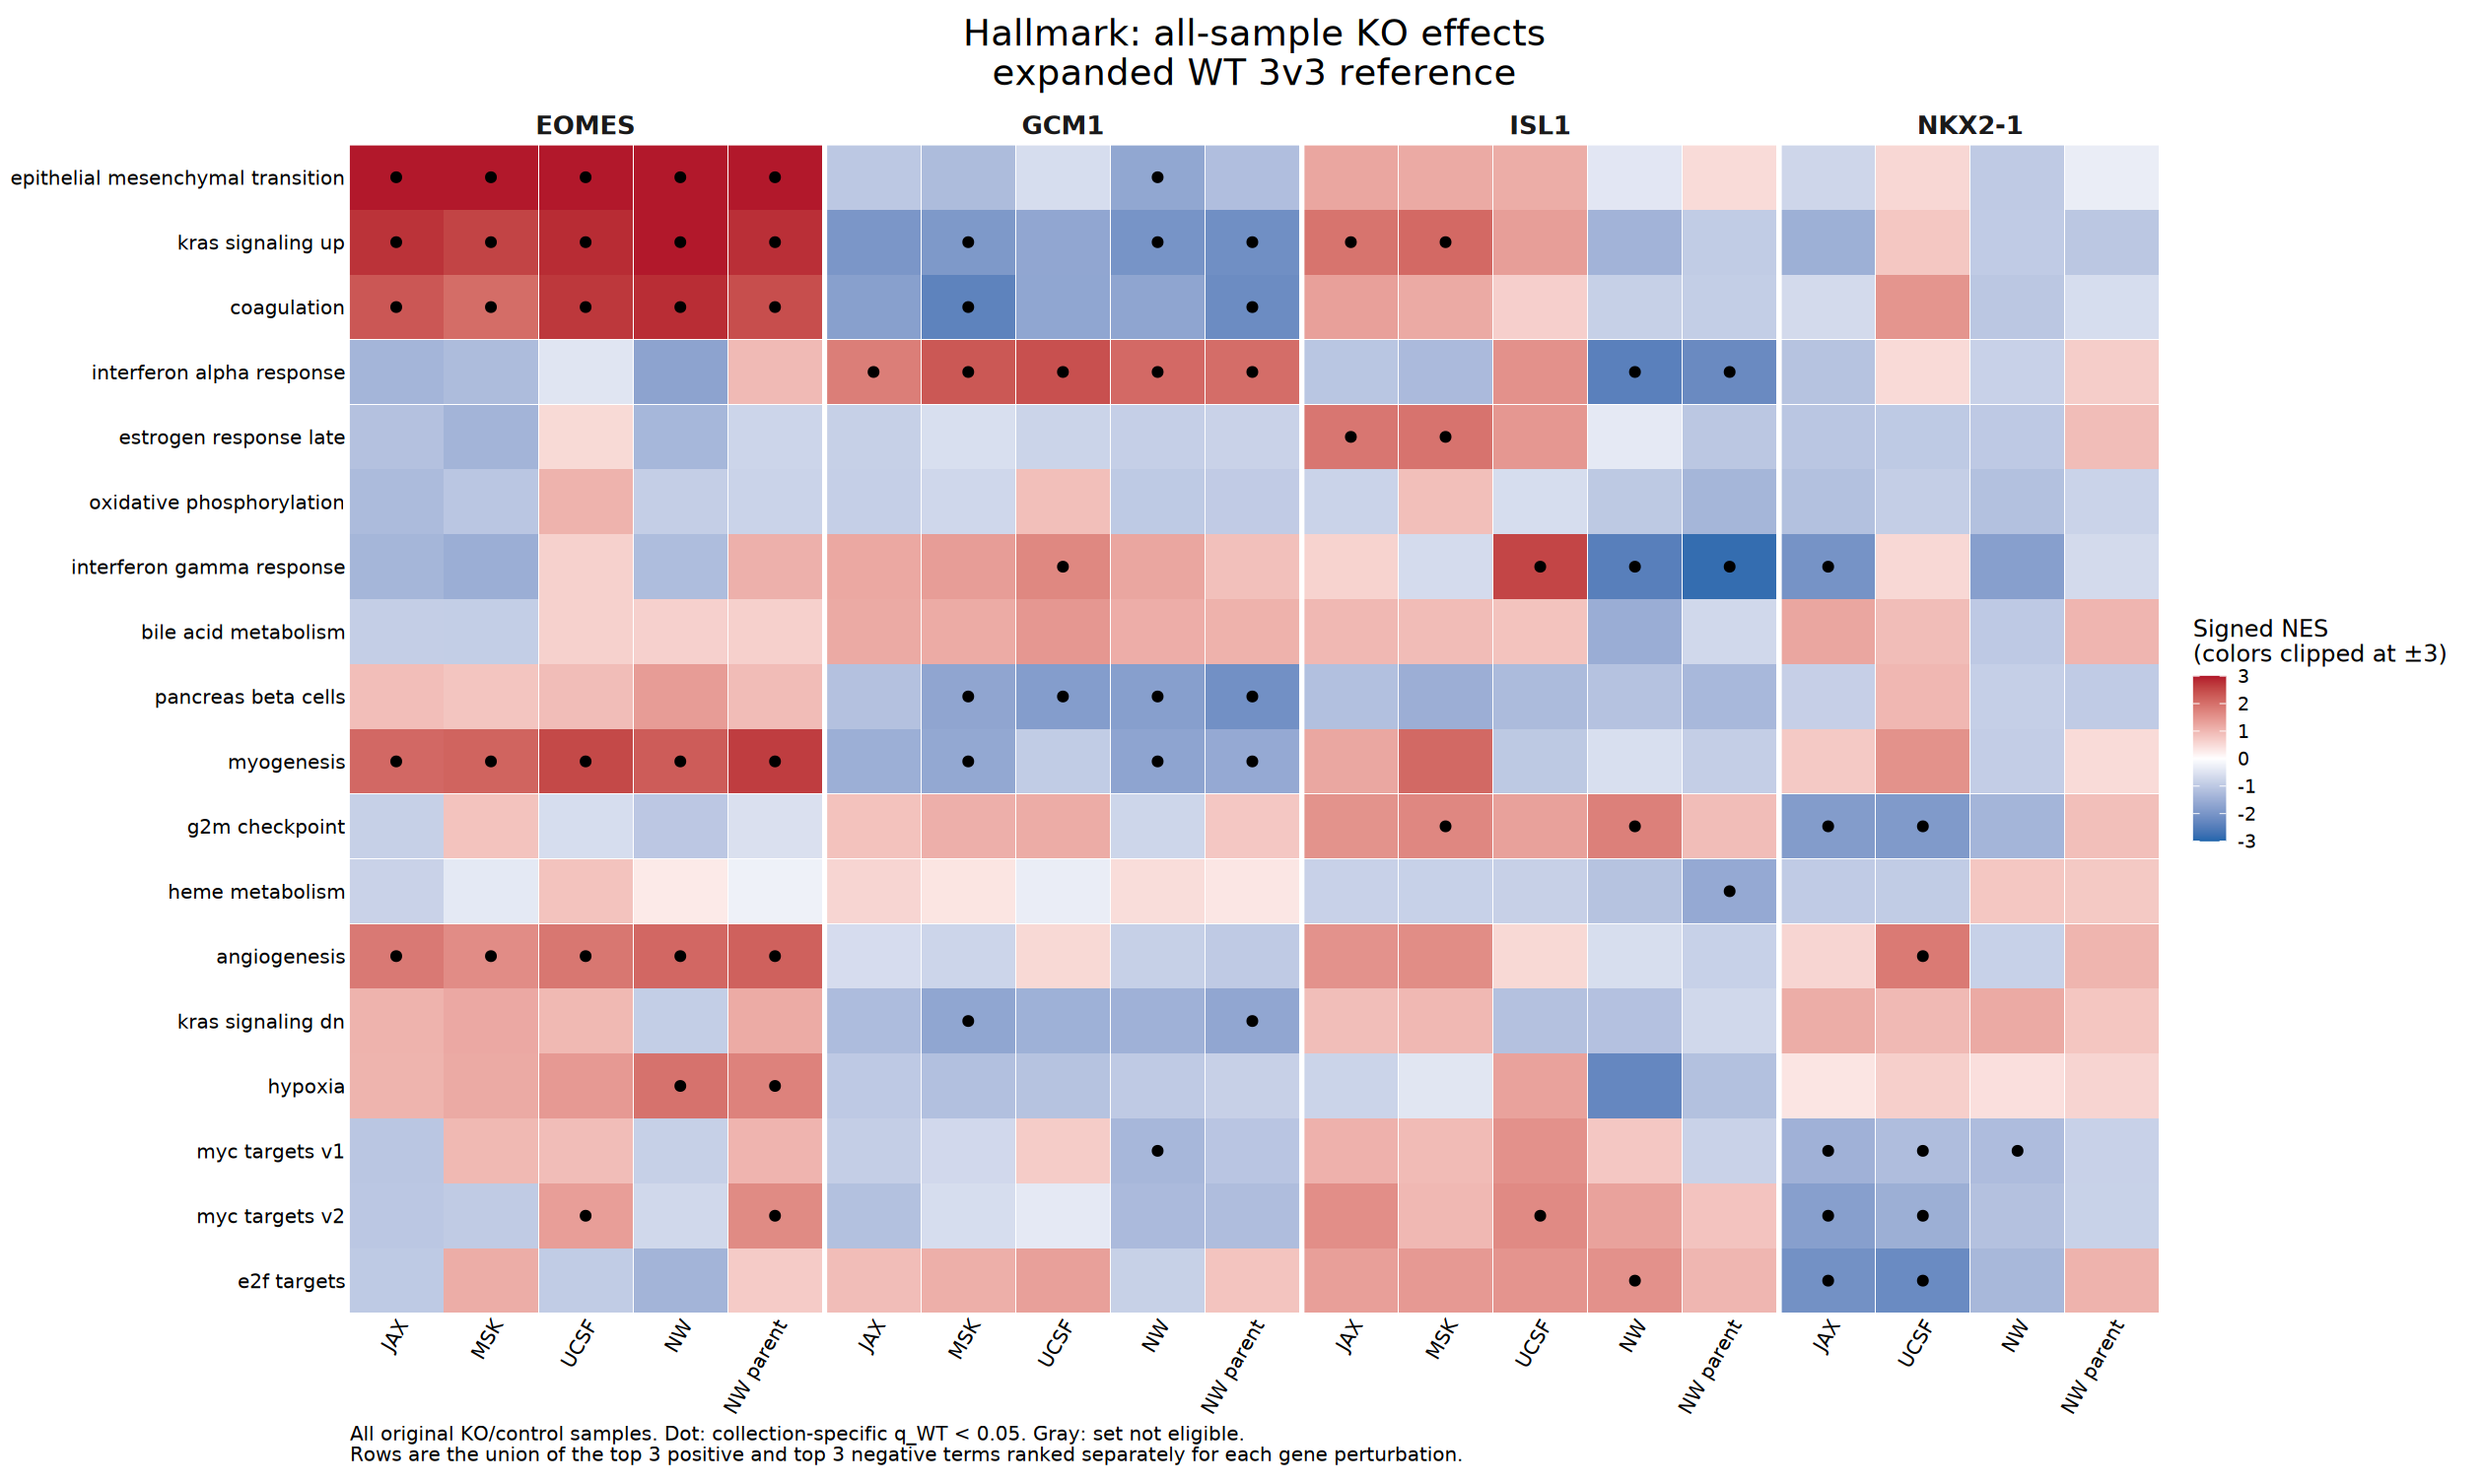

In [11]:
make_full_ko_top_heatmap("Hallmark")

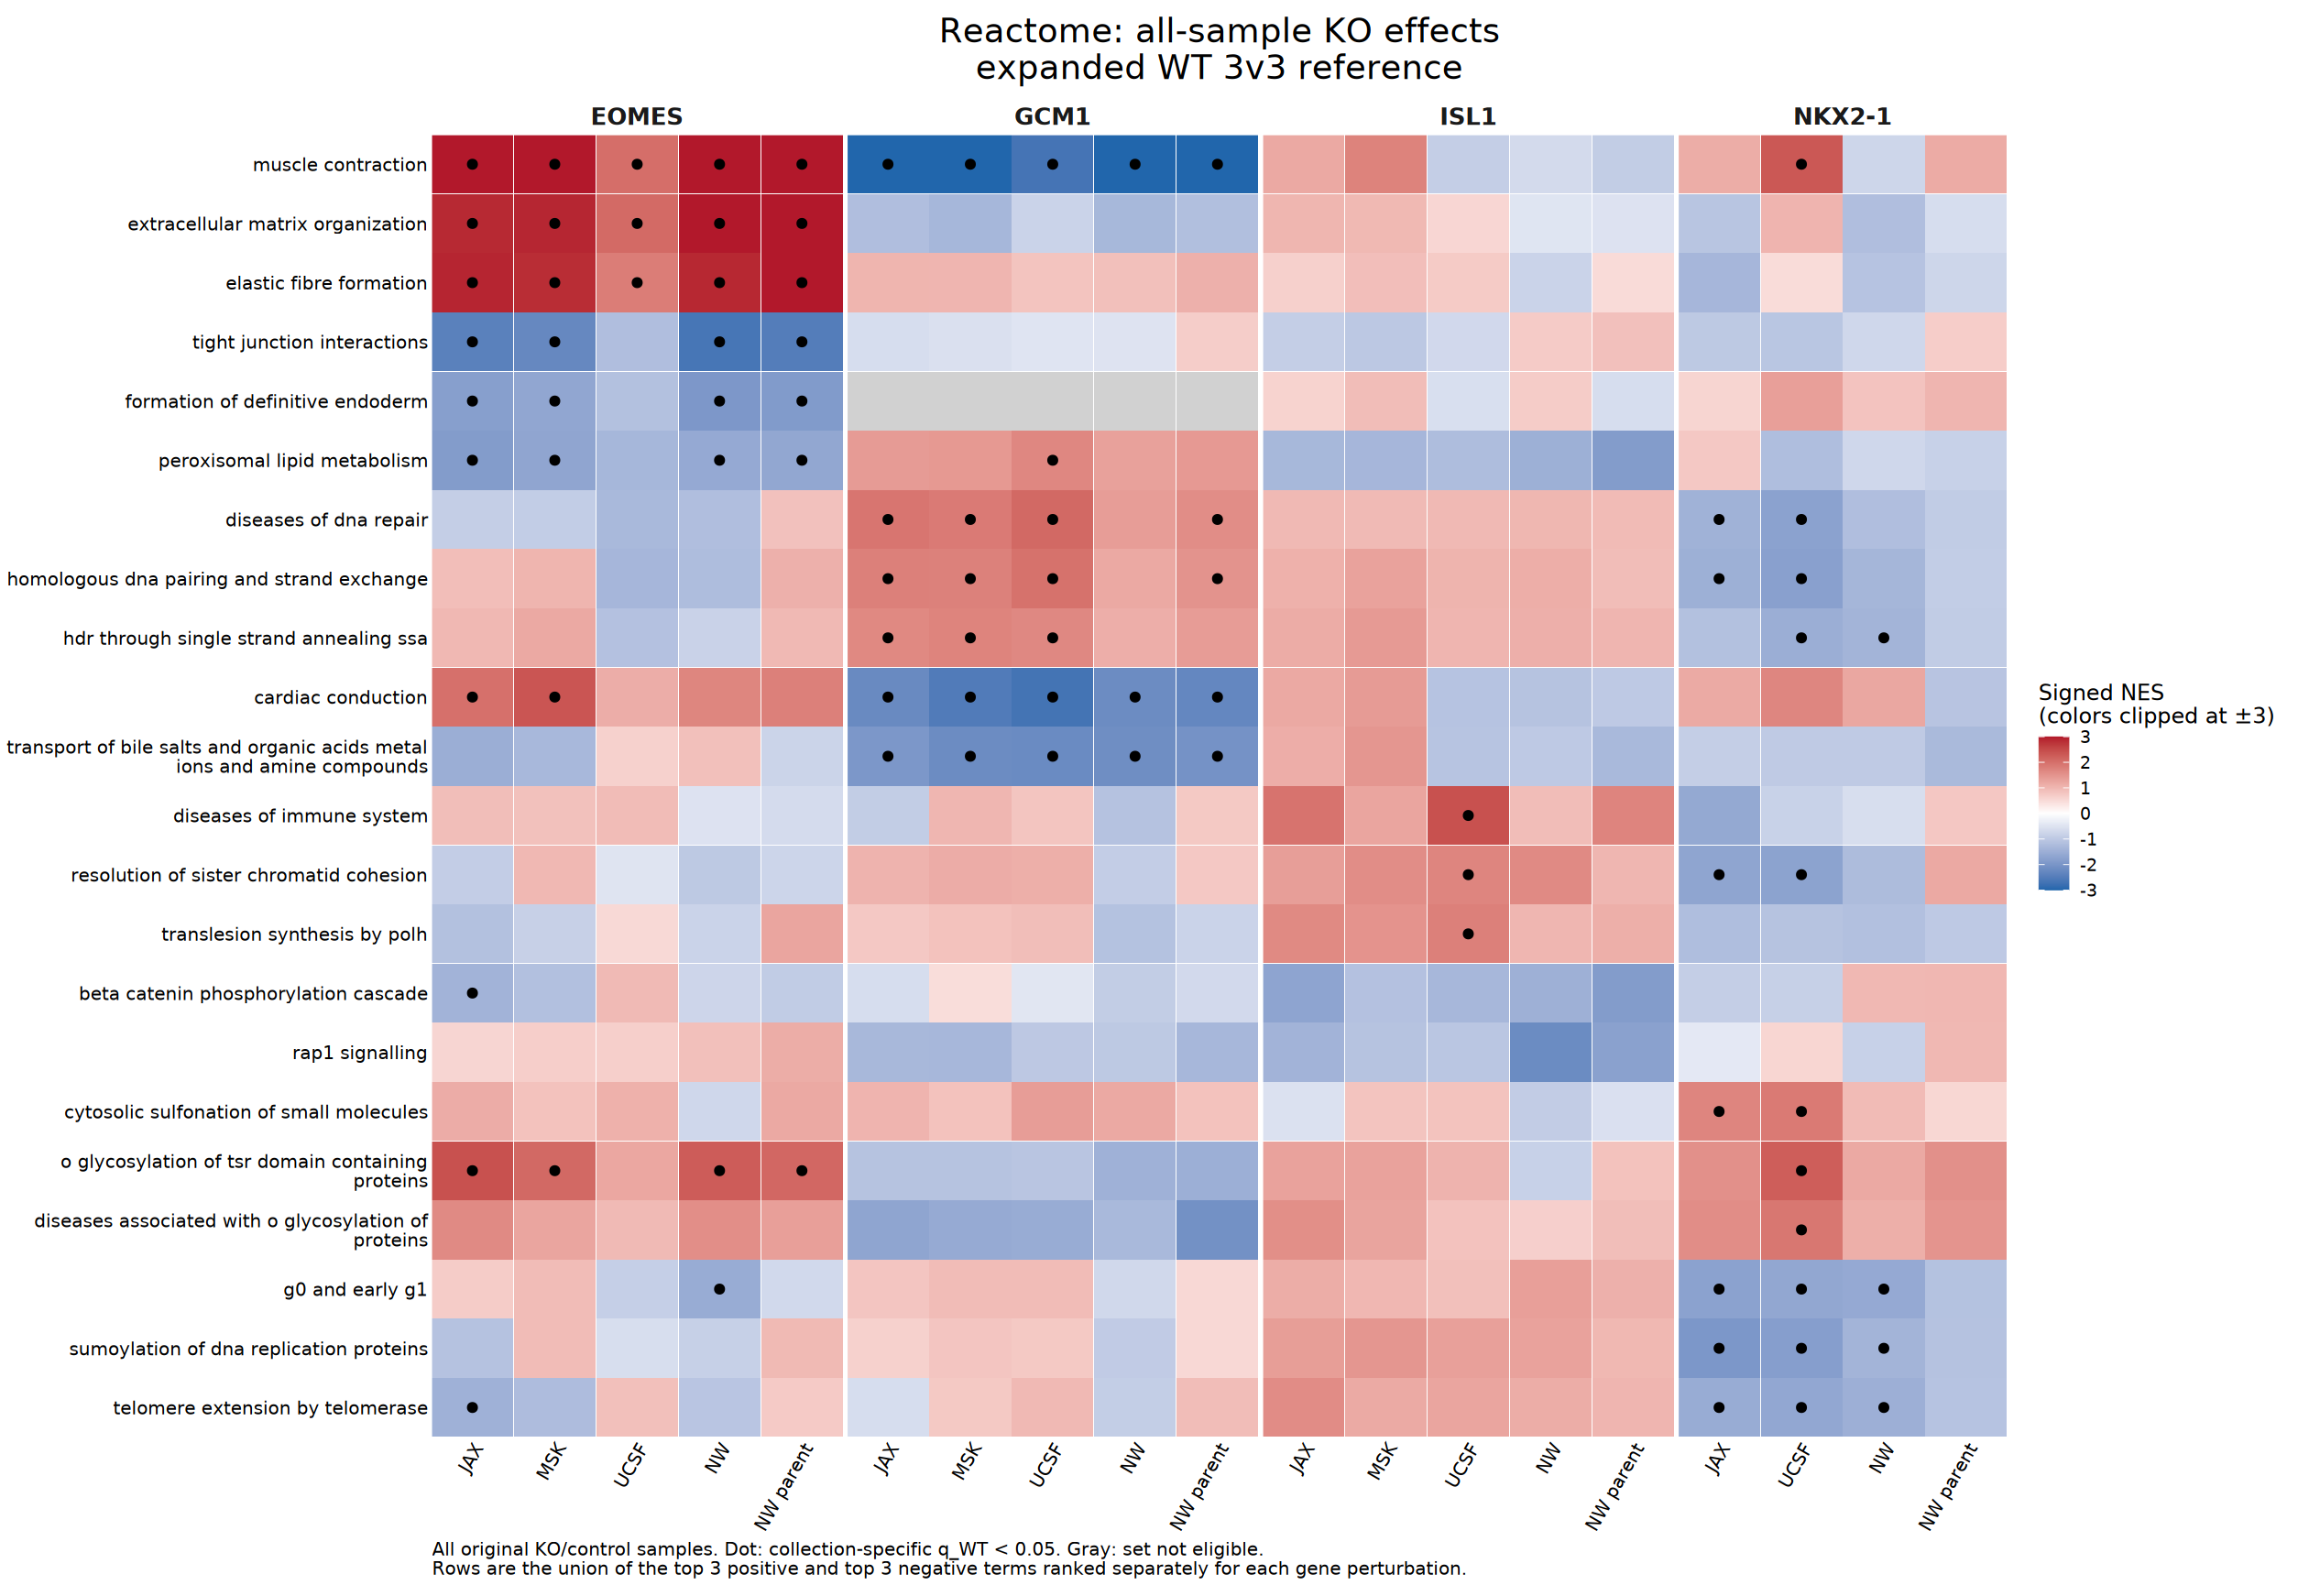

In [12]:
make_full_ko_top_heatmap("Reactome")

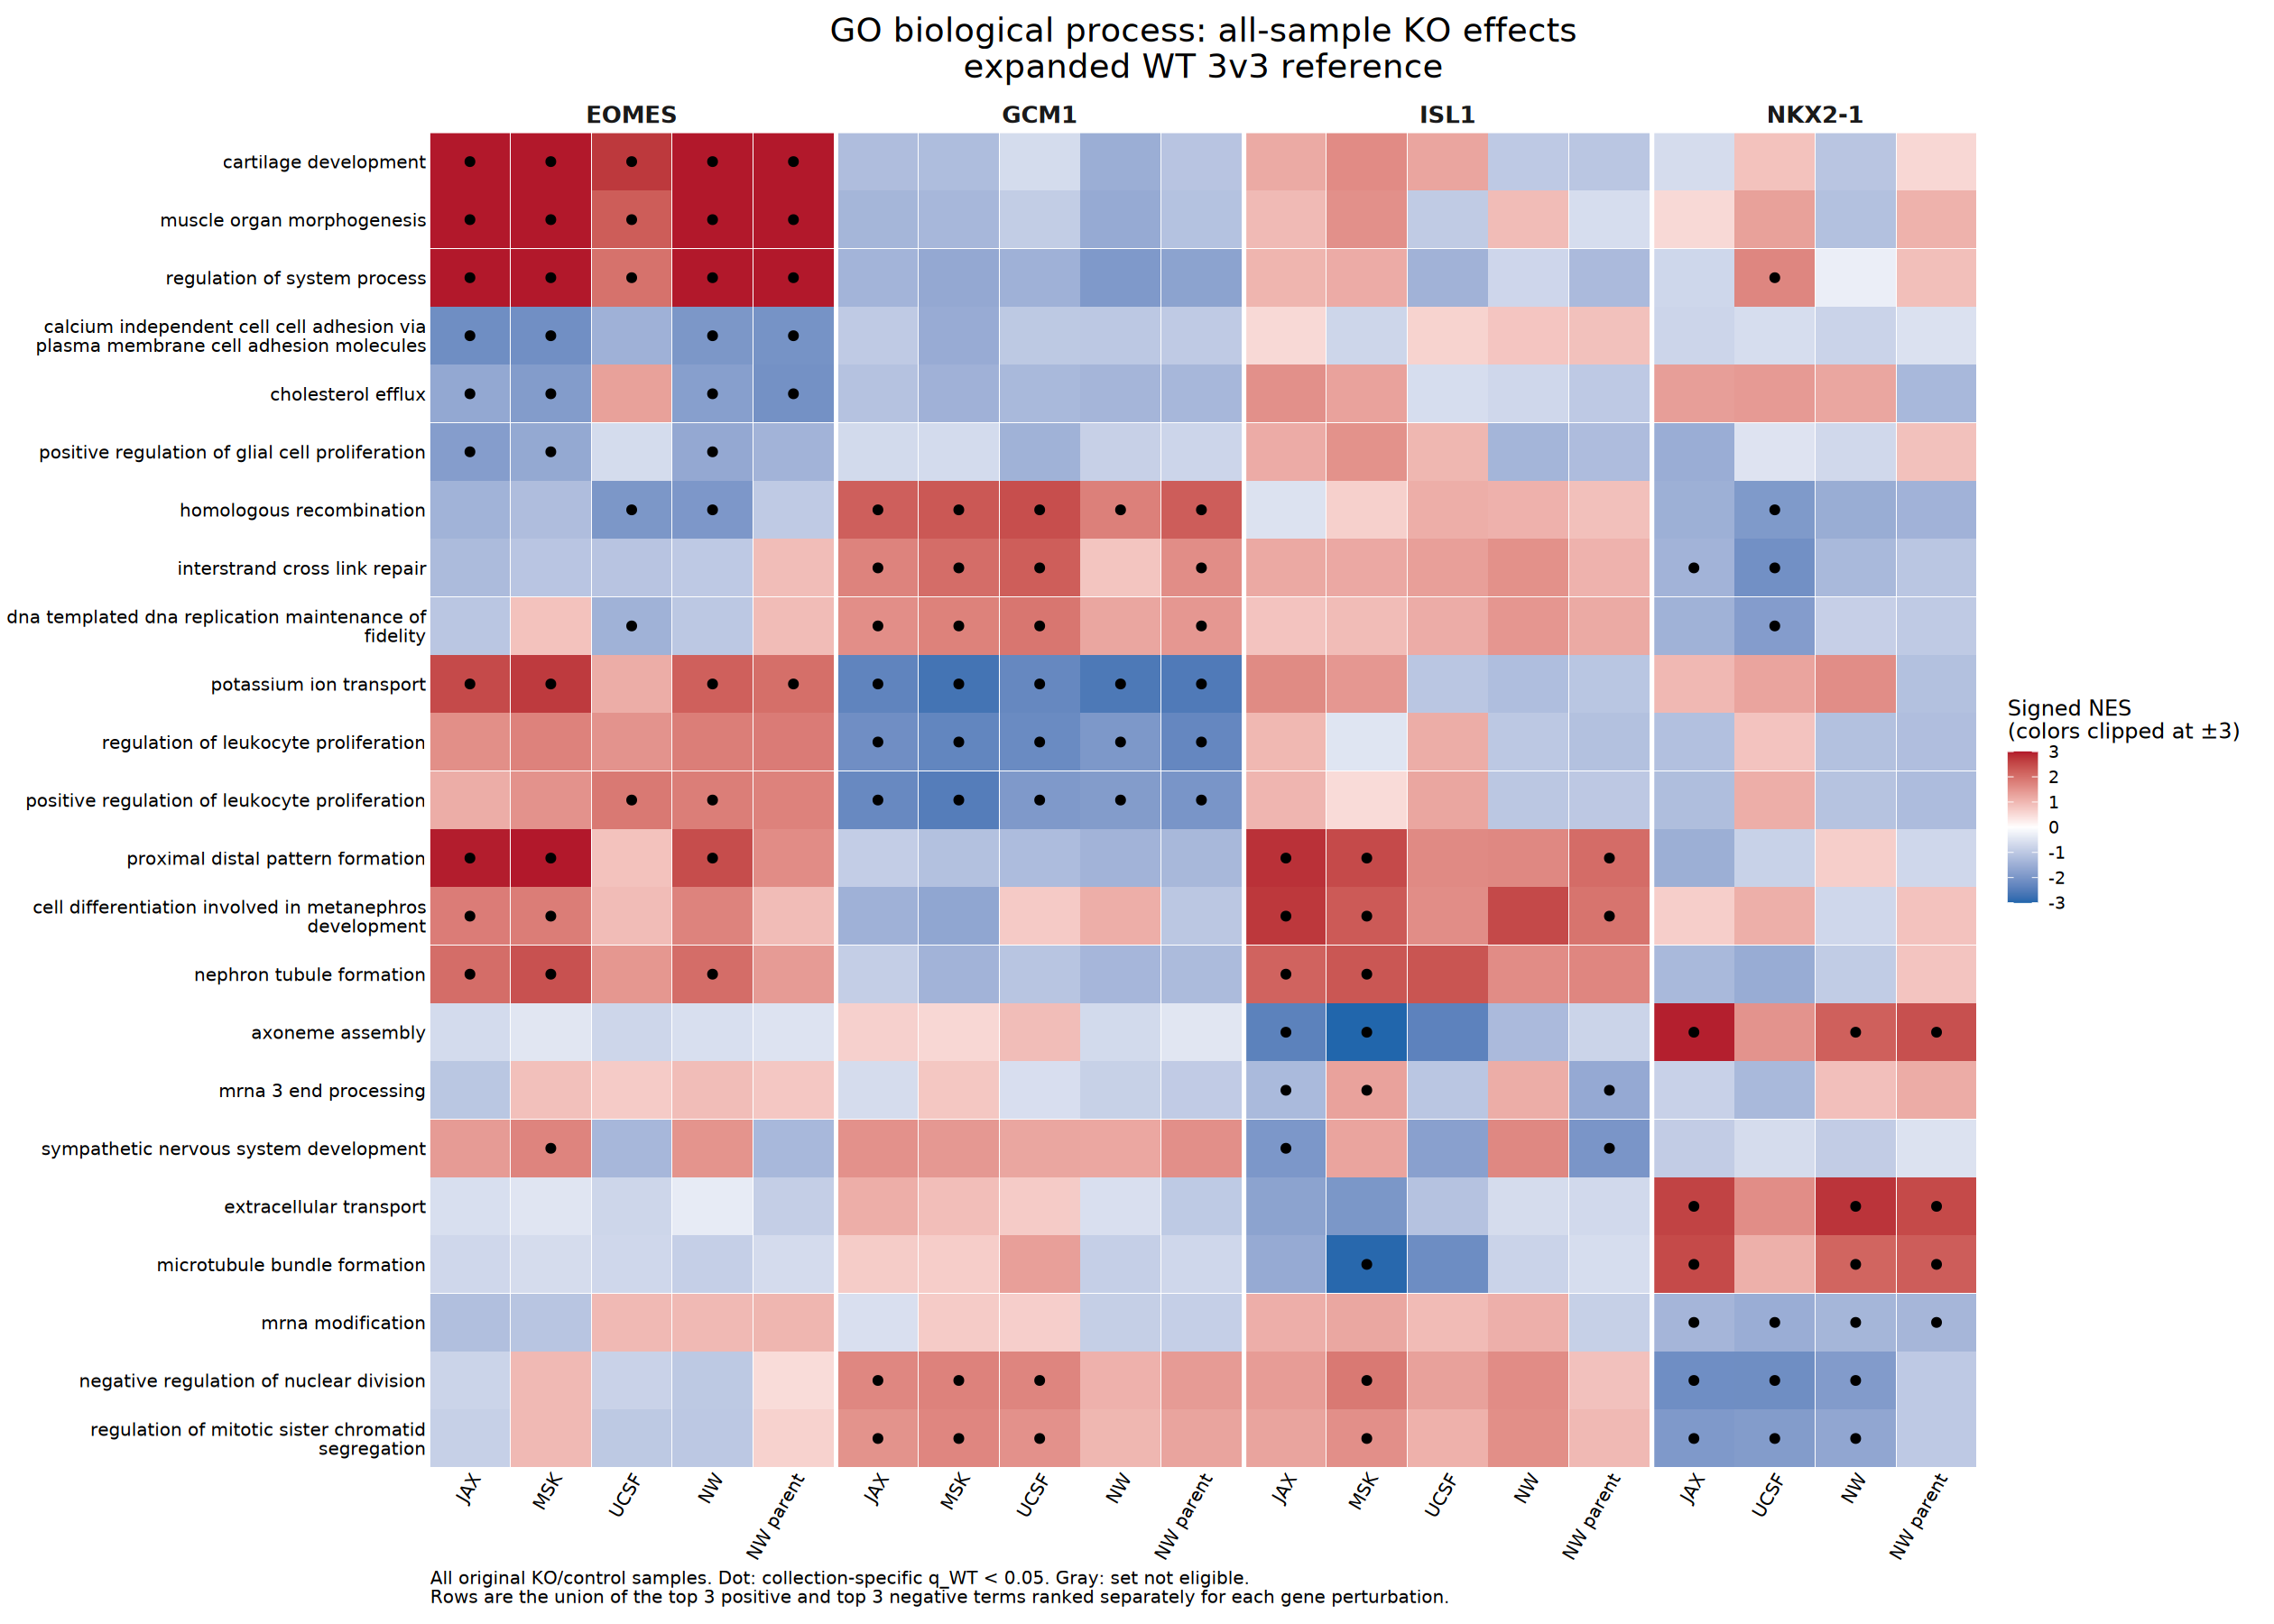

In [13]:
make_full_ko_top_heatmap("GO_BP")

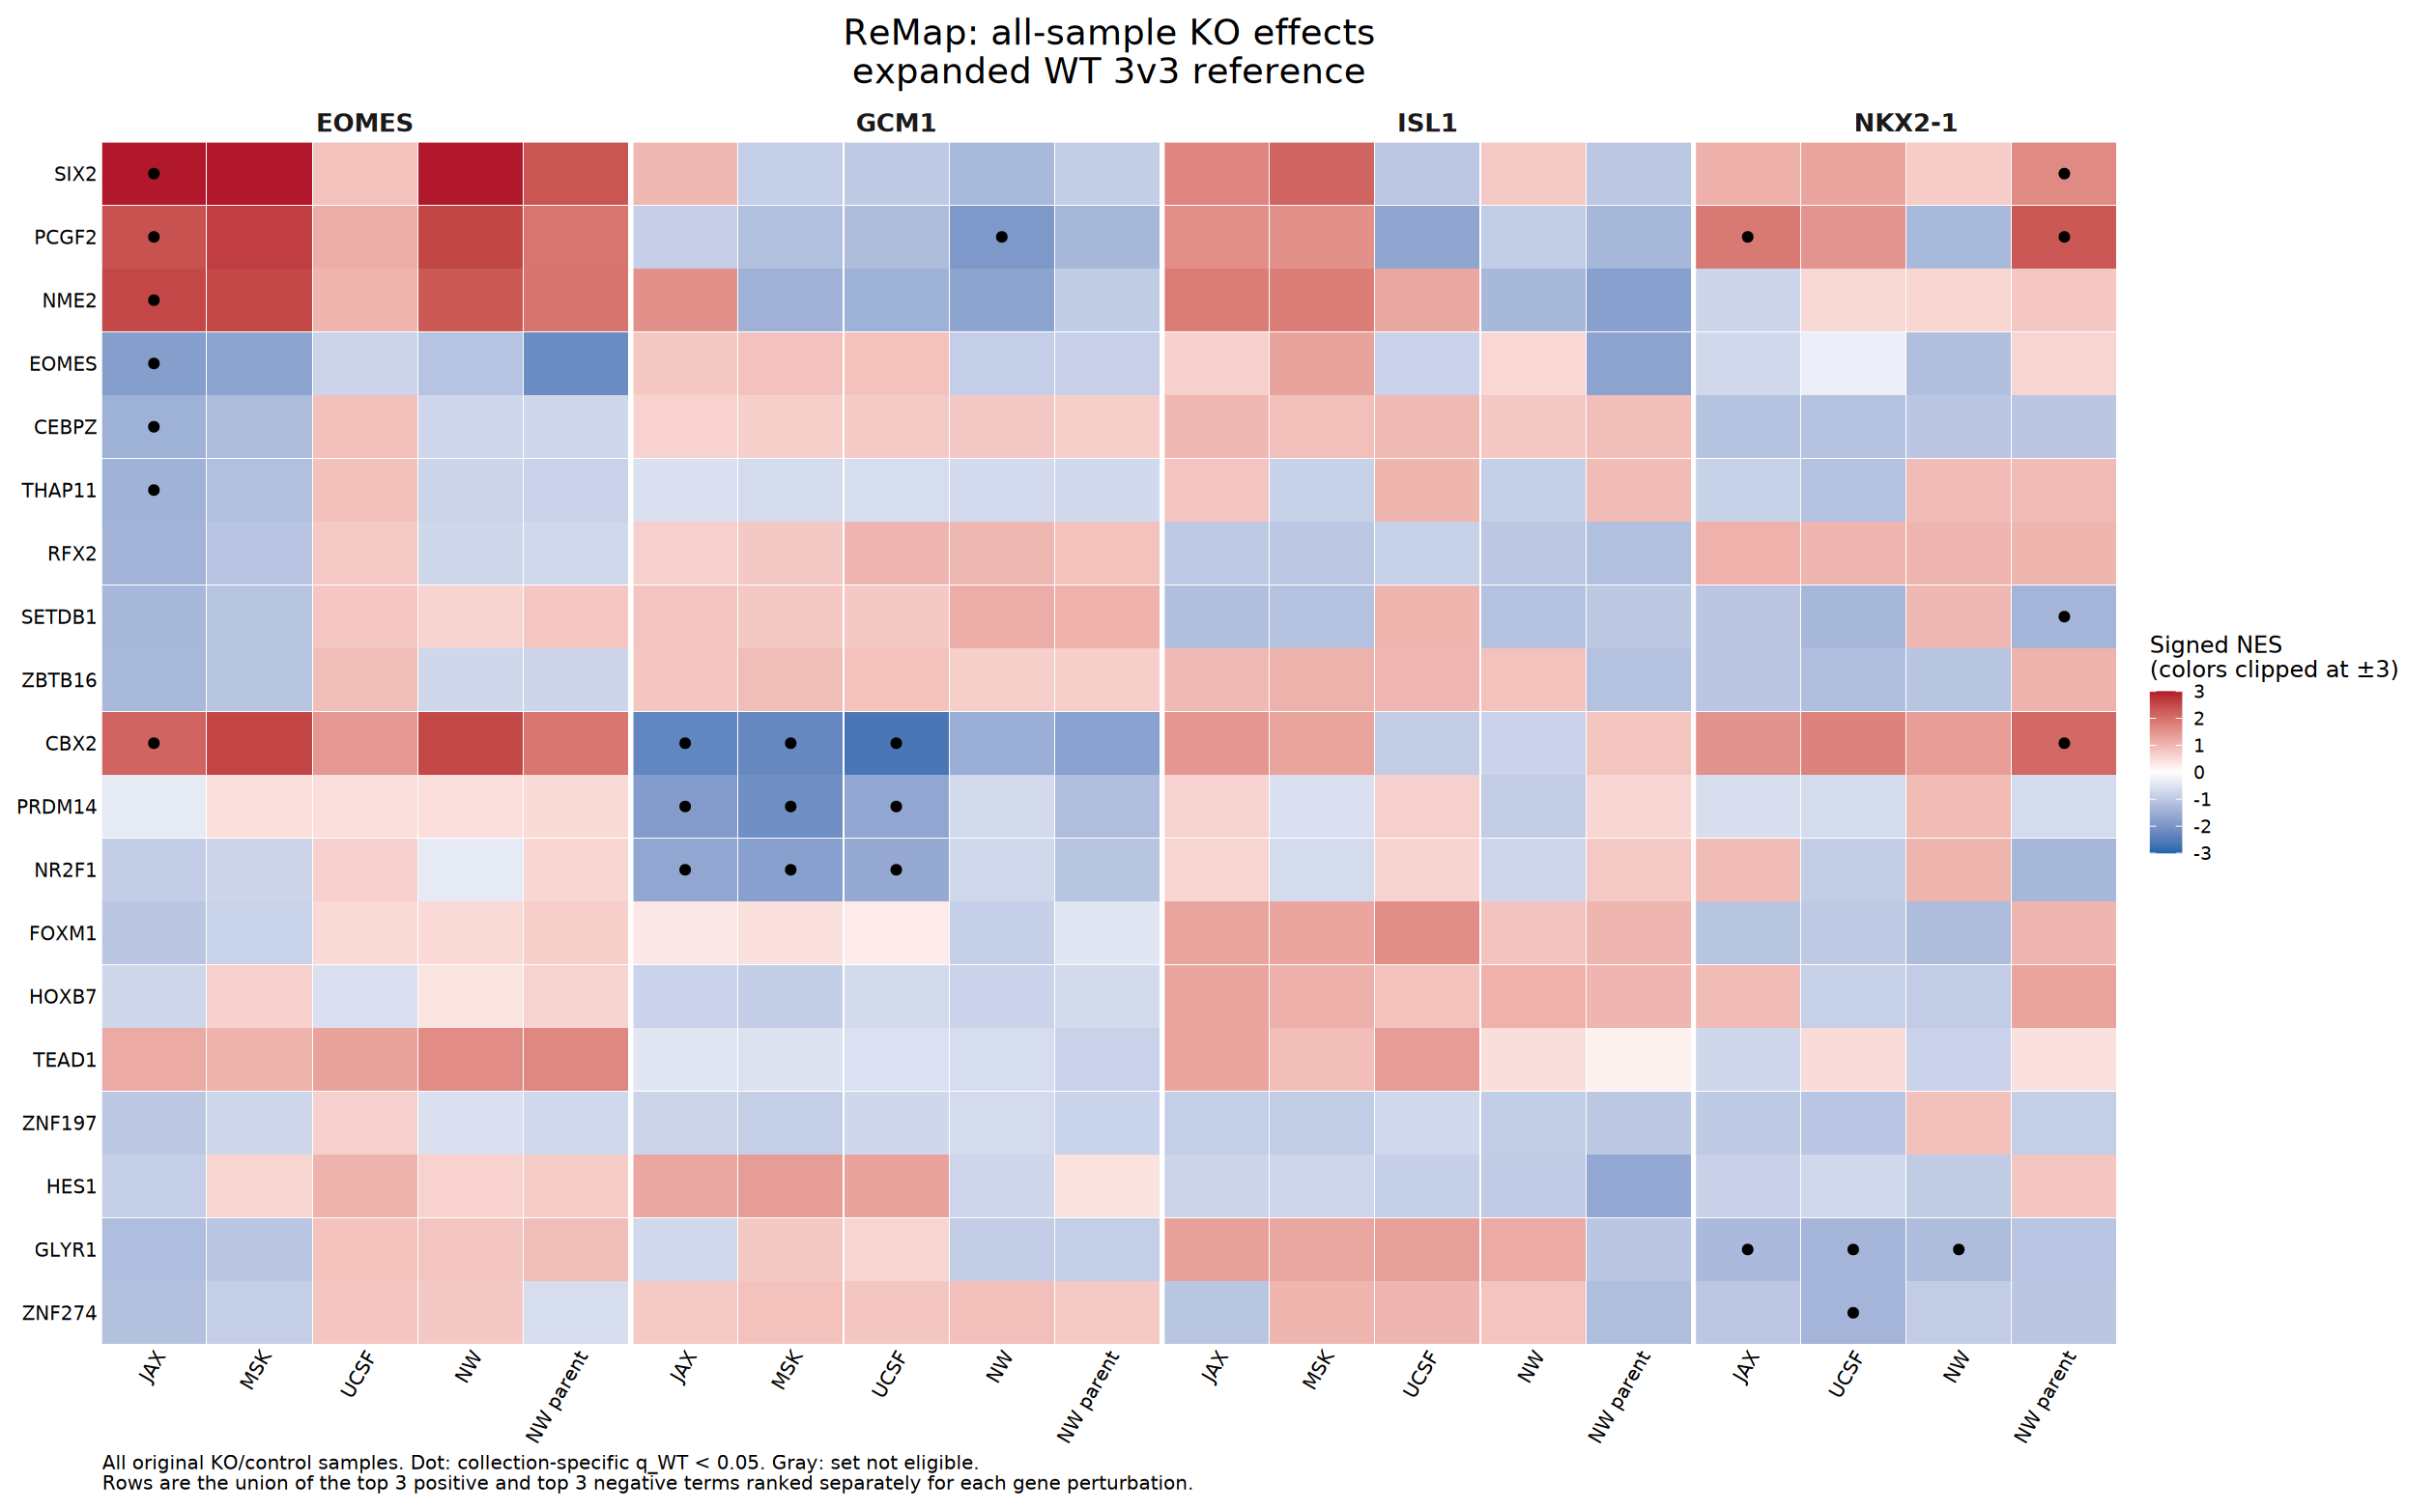

In [14]:
make_full_ko_top_heatmap("ReMap")

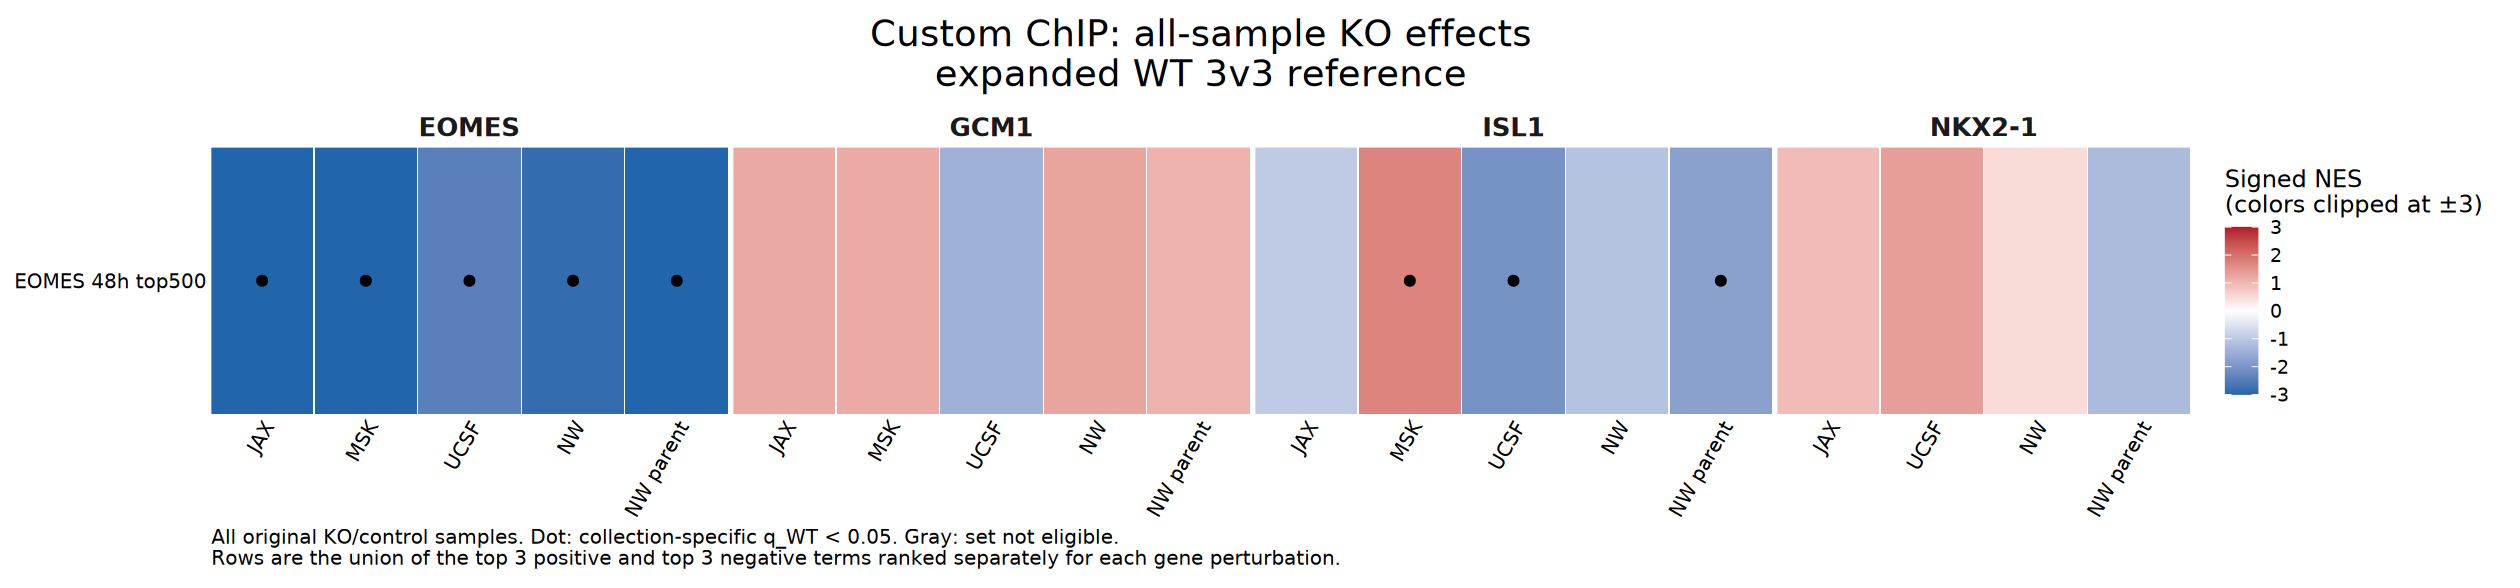

In [15]:
make_full_ko_top_heatmap("Custom_ChIP")

## Interpretation notes

- Ranking is performed within collection because each q-value belongs to a different BH family. A rank of 1 in ReMap is not directly equivalent to a rank of 1 in GO BP.
- The consistency flags summarize recurrence across the available experimental implementations; they do not make those comparisons independent replicates and do not provide a pooled significance test.
- The expanded WT reference contains overlapping WT assignments. More assignments improve empirical resolution but do not create additional biological replicates.
- GO BP contains many overlapping terms, so closely related biological themes can occupy several high ranks. Interpret clusters of related terms rather than treating each label as an independent discovery.
- The complete source table remains unchanged, but NKX2-1/MSK is excluded from this notebook's term selection and heatmaps because of its documented differentiation failure.
- ReMap enrichment indicates that an annotated TF target set is shifted in the ranked list; it does not establish TF activity or direct causality.